VST a nivel oracion 
1. Secuencia de frames (t,c,96,96)
2. CNN - feature extreactor - reducir dimensiones y preservar T 
3. GRU/LSTM - modelado temporal 
4. Clasificación + CTC : 71 clases de caracteres, incluido blank 

In [1]:
import json
import math
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pyarrow

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibilidad
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configuración
CLIPS_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = CLIPS_DIR / "metadata.json"

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

INPUT_CHANNELS = 3  # Provisional: mas adelante enfrentamos a grayscale
VOCAB_SIZE = 71     # 70 caracteres + CTC blank

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Device:", DEVICE)
print("Metadata existe:", METADATA_PATH.exists())
print("Vocabulario:", VOCAB_SIZE)

PyTorch: 2.6.0+cu126
CUDA disponible: True
Device: cuda
Metadata existe: True
Vocabulario: 71


In [2]:
from collections import Counter
from pathlib import Path

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

all_text = "".join(
    info["label"] for info in metadata.values()
)

char_counts = Counter(all_text)

characters = sorted(char_counts.keys())

print(f"Cantidad de caracteres distintos: {len(characters)}")
print(f"Cantidad total con CTC blank: {len(characters) + 1}")
print("\nVocabulario:")
for i, char in enumerate(characters, start=1):
    print(f"{i:2} | {repr(char):8} | frecuencia: {char_counts[char]}")

print("\nCTC blank: 0")

Cantidad de caracteres distintos: 70
Cantidad total con CTC blank: 71

Vocabulario:
 1 | ' '      | frecuencia: 16524
 2 | '0'      | frecuencia: 57
 3 | '1'      | frecuencia: 29
 4 | '2'      | frecuencia: 29
 5 | '3'      | frecuencia: 14
 6 | '4'      | frecuencia: 11
 7 | '5'      | frecuencia: 18
 8 | '6'      | frecuencia: 3
 9 | '7'      | frecuencia: 2
10 | '8'      | frecuencia: 11
11 | '9'      | frecuencia: 8
12 | 'A'      | frecuencia: 72
13 | 'B'      | frecuencia: 25
14 | 'C'      | frecuencia: 97
15 | 'D'      | frecuencia: 29
16 | 'E'      | frecuencia: 139
17 | 'F'      | frecuencia: 12
18 | 'G'      | frecuencia: 17
19 | 'H'      | frecuencia: 26
20 | 'I'      | frecuencia: 15
21 | 'J'      | frecuencia: 6
22 | 'K'      | frecuencia: 10
23 | 'L'      | frecuencia: 56
24 | 'M'      | frecuencia: 51
25 | 'N'      | frecuencia: 47
26 | 'O'      | frecuencia: 18
27 | 'P'      | frecuencia: 86
28 | 'Q'      | frecuencia: 27
29 | 'R'      | frecuencia: 18
30 | 'S'      | f

In [3]:
IMAGE_MODE = "rgb"
INPUT_CHANNELS = 3

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

BLANK_IDX = 0
VOCAB_SIZE = len(characters) + 1

print("Modo de imagen:", IMAGE_MODE)
print("Canales de entrada:", INPUT_CHANNELS)
print("Resolución:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Tamaño del vocabulario:", VOCAB_SIZE)

Modo de imagen: rgb
Canales de entrada: 3
Resolución: 96 x 96
Tamaño del vocabulario: 71


#DATA

In [4]:
DATA_DIR = Path("data")

clips_df = pd.read_parquet(DATA_DIR / "clips_metadata.parquet")
clips_df["path"] = clips_df["path"].apply(Path)

with open(DATA_DIR / "vocabulary.json", "r", encoding="utf-8") as f:
    char_to_idx = json.load(f)

idx_to_char = {
    int(idx): char
    for char, idx in char_to_idx.items()
}

BLANK_IDX = 0
VOCAB_SIZE = len(char_to_idx) + 1

print("Clips:", len(clips_df))
print("Vocabulario:", VOCAB_SIZE)
print("Primer registro:")
display(clips_df.head(1))

Clips: 1304
Vocabulario: 71
Primer registro:


,path,label,frames,ctc_min_frames,repeated_pairs,temporal_margin,min_temporal_ratio,duration_seconds,words_per_second,video_id,is_ctc_problematic,frames_after_x1,margin_after_x1,frames_after_x2,margin_after_x2,frames_after_x3,margin_after_x3,frames_after_x4,margin_after_x4
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108,41,2,67,0.37963,4.32,1.388889,0YEeb-WLF2w,False,108,67,54,13,36,-5,27,-14


In [5]:
class ViSpeRDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        cap = cv2.VideoCapture(str(row["path"]))

        if not cap.isOpened():
            raise RuntimeError(f"No se pudo abrir: {row['path']}")

        frames = []

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

        cap.release()

        if not frames:
            raise RuntimeError(f"El clip no contiene frames: {row['path']}")

        video = np.stack(frames).astype(np.float32) / 255.0
        video = torch.from_numpy(video).permute(0, 3, 1, 2)

        target = torch.tensor(
            [char_to_idx[char] for char in str(row["label"])],
            dtype=torch.long
        )

        return {
            "video": video,
            "target": target,
            "input_length": video.shape[0],
            "target_length": target.numel(),
            "text": str(row["label"]),
            "path": str(row["path"])
        }

la STCNN va a procesar grupos de frames simultaneamente (menos mal)
Los videos tienen 3 dim relevantes_> h,w,t
conv3d , cada frame va a observar una secuencia, y va a extraer caract de eso
approx 1 +3(3-1) /(25fps) = 0.28s de contexto local 

In [6]:

class STCNN(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.BatchNorm3d(in_channels),
            nn.Conv3d(
                in_channels, 32,
                kernel_size=(3, 5, 5),
                stride=(1, 2, 2),
                padding=(1, 2, 2)
            ),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.1)
        )

        self.block2 = nn.Sequential(
            nn.Conv3d(
                32, 64,
                kernel_size=(3, 5, 5),
                stride=(1, 1, 1),
                padding=(1, 2, 2)
            ),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.1)
        )

        self.block3 = nn.Sequential(
            nn.Conv3d(
                64, 96,
                kernel_size=(3, 3, 3),
                stride=(1, 1, 1),
                padding=(1, 1, 1)
            ),
            nn.BatchNorm3d(96),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
        )

    def apply_temporal_mask(self, x, lengths):
        # x: (B, C, T, H, W)
        temporal_size = x.size(2)

        valid_positions = (
            torch.arange(temporal_size, device=x.device)[None, :]
            < lengths.to(x.device)[:, None]
        )

        # (B, 1, T, 1, 1)
        mask = valid_positions[:, None, :, None, None]

        return x * mask

    def forward(self, x, lengths):
        x = self.block1(x)
        x = self.apply_temporal_mask(x, lengths)

        x = self.block2(x)
        x = self.apply_temporal_mask(x, lengths)

        x = self.block3(x)
        x = self.apply_temporal_mask(x, lengths)

        return x


In [7]:
# test ficticio 
model_cnn = STCNN(in_channels=INPUT_CHANNELS)
lengths = torch.tensor([75, 75])

x = torch.randn(2, 3, 75, 96, 96)

with torch.no_grad():
    features = model_cnn(x,lengths)

print("Input:", x.shape)
print("Output:", features.shape)

assert features.shape == (2, 96, 75, 6, 6)

print("Dimensiones verificadas correctamente.")

Input: torch.Size([2, 3, 75, 96, 96])
Output: torch.Size([2, 96, 75, 6, 6])
Dimensiones verificadas correctamente.


### preparar la salida a la recurrente 
$ F = 96 \times 6 \times 6 = 3456 $  

cada frame va a quedar representado por un vector de 3456 características. nothermione,notme,you

In [8]:
# (B, C, T, H, W) -> (T, B, C, H, W)
features = features.permute(2, 0, 1, 3, 4)

# (T, B, C, H, W) -> (T, B, F)
features = features.reshape(
    features.shape[0],
    features.shape[1],
    -1
)

print("Features para la RNN:", features.shape)

assert features.shape == (75, 2, 3456)

Features para la RNN: torch.Size([75, 2, 3456])


In [9]:
class TemporalEncoder(nn.Module):
    def __init__(
        self,
        input_size=3456,
        hidden_size=256,
        num_layers=2,
        rnn_type="gru"
    ):
        super().__init__()

        if rnn_type.lower() == "gru":
            rnn_class = nn.GRU
        elif rnn_type.lower() == "lstm":
            rnn_class = nn.LSTM
        else:
            raise ValueError("rnn_type debe ser 'gru' o 'lstm'")

        self.rnn = rnn_class(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=False
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=False,
            enforce_sorted=False
        )

        packed_output, _ = self.rnn(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=False,
            total_length=x.size(0)
        )

        return output

In [10]:
class CharacterClassifier(nn.Module):
    def __init__(self, input_size=512, vocab_size=VOCAB_SIZE):
        super().__init__()
        self.linear = nn.Linear(input_size, vocab_size)

    def forward(self, x):
        return self.linear(x)

#cosillas:
la entrada es lo que devuelve el dataLoader -> $(B,T,C,H,W)$
La salida queda en (T,B,V), que es el formato que quiere CTCLoss

In [11]:
class LipReadingModel(nn.Module):
    def __init__(
        self,
        in_channels=3,
        vocab_size=VOCAB_SIZE,
        hidden_size=256,
        rnn_type="gru"
    ):
        super().__init__()

        self.visual_encoder = STCNN(in_channels=in_channels)

        self.temporal_encoder = TemporalEncoder(
            input_size=96 * 6 * 6,
            hidden_size=hidden_size,
            num_layers=2,
            rnn_type=rnn_type
        )

        self.classifier = CharacterClassifier(
            input_size=hidden_size * 2,
            vocab_size=vocab_size
        )

    def forward(self, x, input_lengths):
        # B,T,C,H,W -> B,C,T,H,W
        x = x.permute(0, 2, 1, 3, 4)

        # Extracción de características espacio-temporales
        x = self.visual_encoder(x, input_lengths)

        # B,C,T,H,W -> T,B,C*H*W
        x = x.permute(2, 0, 1, 3, 4)
        x = x.reshape(x.shape[0], x.shape[1], -1)

        # Modelado temporal respetando las longitudes reales
        x = self.temporal_encoder(x, input_lengths)

        # Clasificación por timestep
        x = self.classifier(x)

        return torch.log_softmax(x, dim=-1)

In [12]:
train_dataset = ViSpeRDataset(clips_df) 

sample = train_dataset[0]

print("Video:", sample["video"].shape)
print("Tipo:", sample["video"].dtype)
print("Rango:", sample["video"].min().item(), sample["video"].max().item())
print("Target:", sample["target"].shape)
print("Texto:", sample["text"])

assert sample["video"].ndim == 4
assert sample["video"].shape[1:] == (3, 96, 96)
assert sample["video"].dtype == torch.float32
assert sample["target"].numel() == len(sample["text"])

print("\nValidación correcta.")

Video: torch.Size([108, 3, 96, 96])
Tipo: torch.float32
Rango: 0.0 1.0
Target: torch.Size([39])
Texto:  La ficción es una herramienta poderosa

Validación correcta.


In [13]:
def collate_fn(batch):
    videos = [item["video"] for item in batch]
    targets = [item["target"] for item in batch]

    input_lengths = torch.tensor(
        [video.shape[0] for video in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [target.numel() for target in targets],
        dtype=torch.long
    )

    max_frames = input_lengths.max().item()

    padded_videos = torch.zeros(
        len(batch),
        max_frames,
        *videos[0].shape[1:],
        dtype=torch.float32
    )

    for i, video in enumerate(videos):
        padded_videos[i, :video.shape[0]] = video

    concatenated_targets = torch.cat(targets)

    return {
        "videos": padded_videos,
        "targets": concatenated_targets,
        "input_lengths": input_lengths,
        "target_lengths": target_lengths,
        "texts": [item["text"] for item in batch],
        "paths": [item["path"] for item in batch]
    }

In [14]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

batch = next(iter(train_loader))

print("Videos:", batch["videos"].shape)
print("Targets:", batch["targets"].shape)
print("Input lengths:", batch["input_lengths"])
print("Target lengths:", batch["target_lengths"])
print("Transcripciones:")

for text in batch["texts"]:
    print(repr(text))

Videos: torch.Size([2, 108, 3, 96, 96])
Targets: torch.Size([61])
Input lengths: tensor([108,  82])
Target lengths: tensor([39, 22])
Transcripciones:
' La ficción es una herramienta poderosa'
' Una tecnología blanda'


In [15]:
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

blank=0: indice blank  
reduction="mean": promedia la pérdida del batch.  
zero_infinity=True: evita que pérdidas infinitas por alineaciones imposibles contaminen el entrenamiento.  

In [16]:
# la funcion de perdida 
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

## TRAIN

In [17]:
print("Columnas:", clips_df.columns.tolist())

display(clips_df[["path", "label", "frames"]].head())

print("\nCantidad de clips:", len(clips_df))

Columnas: ['path', 'label', 'frames', 'ctc_min_frames', 'repeated_pairs', 'temporal_margin', 'min_temporal_ratio', 'duration_seconds', 'words_per_second', 'video_id', 'is_ctc_problematic', 'frames_after_x1', 'margin_after_x1', 'frames_after_x2', 'margin_after_x2', 'frames_after_x3', 'margin_after_x3', 'frames_after_x4', 'margin_after_x4']


,path,label,frames
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108
1,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00001.mp4,Una tecnología blanda,82
2,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00002.mp4,Las tecnologías blandas funcionan de la misma...,79
3,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00003.mp4,Cuando en las historias de la Biblia se nos c...,178
4,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00004.mp4,que las cosas buenas son recompensadas y las ...,110



Cantidad de clips: 1304


In [18]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=18
)

train_idx, test_idx = next(
    splitter.split(
        clips_df,
        groups=clips_df["video_id"]
    )
)

train_df = clips_df.iloc[train_idx].reset_index(drop=True)
test_df = clips_df.iloc[test_idx].reset_index(drop=True)

print("TRAIN")
print("Videos:", train_df["video_id"].nunique())
print("Clips:", len(train_df))

print("\nTEST")
print("Videos:", test_df["video_id"].nunique())
print("Clips:", len(test_df))

print(
    "\n¿Hay videos compartidos?",
    bool(
        set(train_df["video_id"])
        & set(test_df["video_id"])
    )
)

TRAIN
Videos: 18
Clips: 947

TEST
Videos: 5
Clips: 357

¿Hay videos compartidos? False


In [19]:
from torch.utils.data import DataLoader

train_dataset = ViSpeRDataset(train_df)
test_dataset = ViSpeRDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train:", len(train_dataset), "clips |", len(train_loader), "batches")
print("Test:", len(test_dataset), "clips |", len(test_loader), "batches")

Train: 947 clips | 474 batches
Test: 357 clips | 179 batches


In [20]:
model = LipReadingModel(
    in_channels=INPUT_CHANNELS,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)

print("Modelo reinicializado")
print("Dispositivo:", next(model.parameters()).device)

Modelo reinicializado
Dispositivo: cuda:0


# train posta

In [21]:
# ---- Chequeos ANTES de entrenar ----

# 1) El blank (índice 0) no puede ser también un caracter del vocabulario
print("Caracter con índice 0 en el vocabulario:", idx_to_char.get(0, "ninguno (correcto)"))
print("Índice máximo:", max(idx_to_char), "| VOCAB_SIZE:", VOCAB_SIZE)
assert BLANK_IDX not in idx_to_char, "El índice 0 ya es un caracter: choca con el blank de CTC"
assert max(idx_to_char) == VOCAB_SIZE - 1, "VOCAB_SIZE no coincide con los índices del vocabulario"

# 2) Clips donde el texto NO entra en los frames disponibles (CTC imposible)
def min_frames_needed_text(text):
    text = str(text)
    repeats = sum(1 for a, b in zip(text[:-1], text[1:]) if a == b)
    return len(text) + repeats

check = clips_df[["label", "frames"]].copy()
check["chars"] = check["label"].astype(str).str.len()
check["needed"] = check["label"].astype(str).apply(min_frames_needed_text)
check["ratio"] = check["needed"] / check["frames"]

impossible = check[check["needed"] > check["frames"]]

print(f"\nClips imposibles para CTC: {len(impossible)}/{len(check)} "
      f"({100 * len(impossible) / len(check):.1f}%)")
print("Ratio (frames necesarios / frames disponibles):")
print(check["ratio"].describe().round(3).to_string())

if len(impossible):
    display(impossible.head())


Caracter con índice 0 en el vocabulario: ninguno (correcto)
Índice máximo: 70 | VOCAB_SIZE: 71

Clips imposibles para CTC: 14/1304 (1.1%)
Ratio (frames necesarios / frames disponibles):
count    1304.000
mean        0.600
std         0.165
min         0.080
25%         0.496
50%         0.592
75%         0.699
max         1.200


,label,frames,chars,needed,ratio
24,Esto es lo que hemos visto en las películas y...,50,60,60,1.200000
42,Y en esa época se estaba empezando a hablar d...,61,70,70,1.147541
71,pueden servir para entender lo que no somos c...,63,64,64,1.015873
300,en un momento dado y esto lo podéis ver en In...,70,78,78,1.114286
303,Ayer por la noche vi que la capitalización bu...,54,63,63,1.166667



[época 1/50 | iter 5/474] loss=4.4646 | grad_norm=8.18
  clip 0: 00009.mp4 | frames=180 | caracteres=107 (mín. 107)
    REAL: 'el famoso transporte igual el transporte sponsor del evento que después tuve la alegría de diseñar su marca'
    PRED: ' '
    RAW : ␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣
    blank=0% | más frecuentes: ␣:100%
  clip 1: 00004.mp4 | frames=138 | caracteres=84 (mín. 84)
    REAL: ' o también en nuestros automóviles provenía de combustibles fósiles como el petróleo'
    PRED: ' '
    RAW : ␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣␣
    blank=0% | más frecuentes: ␣:100%

[época 1/50 | iter 10/474] loss=3.5657 | grad_norm=5.94
  clip 0: 00020.mp4 | frames=169 | caracteres=87 (mín. 87)
    REAL: ' El 20 de diciembre del 2020 fue que

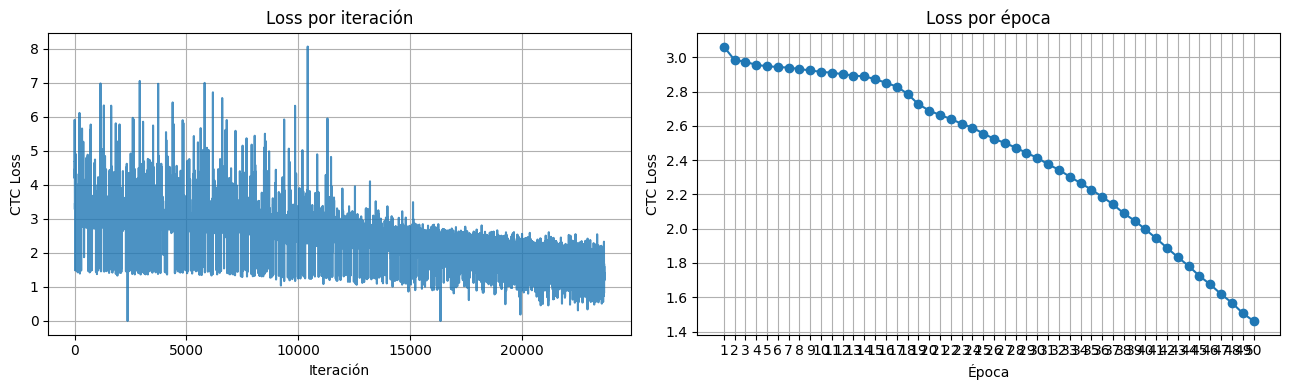

In [22]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter
from pathlib import Path

EPOCHS = 50
PRINT_EVERY = 5      # imprime el detalle cada N iteraciones (1 = todas)

ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)


# ---------- helpers para ver qué está prediciendo ----------
def tok_to_symbol(tok):
    """blank -> '·' | espacio -> '␣' | resto -> el caracter."""
    if tok == BLANK_IDX:
        return "·"
    ch = idx_to_char[tok]
    return "␣" if ch == " " else ch


def raw_frames(tokens):
    """Argmax por frame SIN colapsar: lo que la red dice en cada frame."""
    return "".join(tok_to_symbol(t) for t in tokens)


def ctc_collapse(tokens):
    """Greedy CTC: colapsa repetidos y elimina blanks."""
    out, prev = [], None
    for t in tokens:
        if t != prev and t != BLANK_IDX:
            out.append(idx_to_char[t])
        prev = t
    return "".join(out)


def min_frames_needed(target_tokens):
    """Frames mínimos para alinear el target: 1 por caracter
    + 1 blank obligatorio entre cada par de caracteres iguales seguidos."""
    repeats = sum(1 for a, b in zip(target_tokens[:-1], target_tokens[1:]) if a == b)
    return len(target_tokens) + repeats


def top_tokens(tokens, k=3):
    total = len(tokens)
    return " ".join(
        f"{tok_to_symbol(t)}:{100 * n / total:.0f}%"
        for t, n in Counter(tokens).most_common(k)
    )


# ---------- entrenamiento ----------
history = []         # loss promedio por época
iter_history = []    # loss de cada iteración
n_iters = len(train_loader)

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    valid_batches = 0
    seen_samples = 0
    empty_predictions = 0
    impossible_samples = 0

    for batch_idx, batch in enumerate(train_loader):

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        optimizer.zero_grad()

        log_probs = model(videos, input_lengths)      # (T, B, V)

        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            print(f"[época {epoch + 1} | iter {batch_idx + 1}] loss no finita, se saltea")
            continue

        loss.backward()

        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()
        valid_batches += 1
        iter_history.append(loss.item())

        # ----- qué predijo la red en ESTA iteración (mismo forward que la loss) -----
        preds = log_probs.detach().argmax(dim=-1).cpu()     # (T, B)
        cpu_targets = batch["targets"]                      # ya está en CPU
        show = (batch_idx + 1) % PRINT_EVERY == 0

        if show:
            print(
                f"\n[época {epoch + 1}/{EPOCHS} | iter {batch_idx + 1}/{n_iters}] "
                f"loss={loss.item():.4f} | grad_norm={float(grad_norm):.2f}"
            )

        offset = 0

        for i in range(len(input_lengths)):

            T_i = input_lengths[i].item()
            L_i = target_lengths[i].item()

            tgt = cpu_targets[offset:offset + L_i].tolist()
            offset += L_i

            frame_tokens = preds[:T_i, i].tolist()

            reference = "".join(idx_to_char[t] for t in tgt)
            prediction = ctc_collapse(frame_tokens)
            need = min_frames_needed(tgt)
            impossible = need > T_i

            seen_samples += 1
            empty_predictions += int(prediction == "")
            impossible_samples += int(impossible)

            if show:
                blank_pct = 100 * frame_tokens.count(BLANK_IDX) / T_i
                print(f"  clip {i}: {Path(batch['paths'][i]).name} | frames={T_i} | caracteres={L_i} (mín. {need})")
                if impossible:
                    print(f"    ⚠ IMPOSIBLE para CTC: necesita {need} frames y hay {T_i} -> aporta loss=0 por zero_infinity")
                print(f"    REAL: {reference!r}")
                print(f"    PRED: {prediction!r}")
                print(f"    RAW : {raw_frames(frame_tokens)}")
                print(f"    blank={blank_pct:.0f}% | más frecuentes: {top_tokens(frame_tokens)}")

    epoch_loss = total_loss / max(valid_batches, 1)
    history.append(epoch_loss)

    print("\n" + "=" * 60)
    print(
        f"Época {epoch + 1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Batches: {valid_batches}/{n_iters}"
    )
    print(f"  Predicciones vacías: {empty_predictions}/{seen_samples}")
    print(f"  Clips imposibles para CTC: {impossible_samples}/{seen_samples}")
    print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(iter_history, alpha=0.8)
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("CTC Loss")
axes[0].set_title("Loss por iteración")
axes[0].grid(True)

axes[1].plot(range(1, EPOCHS + 1), history, marker="o")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("CTC Loss")
axes[1].set_title("Loss por época")
axes[1].set_xticks(range(1, EPOCHS + 1))
axes[1].grid(True)

plt.tight_layout()
plt.show()


## eval

In [ ]:
def greedy_decode(log_probs, input_length):
    """
    Convierte las predicciones por timestep en una secuencia
    de caracteres usando greedy decoding + CTC collapse.
    """

    predictions = log_probs[:input_length].argmax(dim=-1).tolist()

    decoded = []
    previous = None

    for token in predictions:

        if token != previous and token != BLANK_IDX:
            decoded.append(idx_to_char[token])

        previous = token

    return "".join(decoded)

In [ ]:

def edit_distance(reference, hypothesis):
    """
    Distancia de Levenshtein:
    sustituciones + inserciones + eliminaciones.
    """

    rows = len(reference) + 1
    cols = len(hypothesis) + 1

    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):

            if reference[i - 1] == hypothesis[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,       # Eliminación
                dp[i][j - 1] + 1,       # Inserción
                dp[i - 1][j - 1] + cost  # Sustitución
            )

    return dp[-1][-1]


In [ ]:
def normalize_text(text):
    """
    Normalización mínima para comparar transcripciones.
    """

    return " ".join(text.lower().split())


In [ ]:
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

In [ ]:
model.eval()

total_loss = 0.0
valid_batches = 0

total_char_errors = 0
total_chars = 0

total_word_errors = 0
total_words = 0

results = []

with torch.no_grad():

    for batch in test_loader:

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        # Forward
        log_probs = model(videos, input_lengths)

        # CTC Loss
        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if torch.isfinite(loss):
            total_loss += loss.item()
            valid_batches += 1

        # Decodificar cada video del batch
        target_offset = 0

        for i in range(len(input_lengths)):

            # Predicción
            prediction = greedy_decode(
                log_probs[:, i, :],
                input_lengths[i].item()
            )

            # Target correspondiente al video
            target_length = target_lengths[i].item()

            target = targets[
                target_offset:target_offset + target_length
            ].tolist()

            reference = "".join(
                idx_to_char[token]
                for token in target
            )

            target_offset += target_length

            # Normalización
            reference_norm = normalize_text(reference)
            prediction_norm = normalize_text(prediction)

            # CER
            char_errors = edit_distance(
                reference_norm,
                prediction_norm
            )

            total_char_errors += char_errors
            total_chars += len(reference_norm)

            # WER
            reference_words = reference_norm.split()
            prediction_words = prediction_norm.split()

            word_errors = edit_distance(
                reference_words,
                prediction_words
            )

            total_word_errors += word_errors
            total_words += len(reference_words)

            results.append({
                "reference": reference,
                "prediction": prediction,
                "char_errors": char_errors,
                "word_errors": word_errors
            })

In [26]:
test_loss = (
    total_loss / valid_batches
    if valid_batches > 0 else float("nan")
)

CER = (
    total_char_errors / total_chars
    if total_chars > 0 else float("nan")
)

WER = (
    total_word_errors / total_words
    if total_words > 0 else float("nan")
)

In [27]:
print("=" * 50)
print("RESULTADOS DE EVALUACIÓN")
print("=" * 50)

print(f"Clips evaluados: {len(results)}")
print(f"Test Loss:       {test_loss:.4f}")
print(f"CER:             {CER:.4f} ({CER * 100:.2f}%)")
print(f"WER:             {WER:.4f} ({WER * 100:.2f}%)")

print("\n" + "=" * 50)
print("EJEMPLOS DE PREDICCIONES")
print("=" * 50)

for i, result in enumerate(results[:10]):

    print(f"\nEjemplo {i + 1}")
    print("Real:      ", repr(result["reference"]))
    print("Predicción:", repr(result["prediction"]))
    print("Errores de caracteres:", result["char_errors"])
    print("Errores de palabras:  ", result["word_errors"])


print("\n" + "=" * 50)
print("DISTRIBUCIÓN DE PREDICCIONES")
print("=" * 50)

from collections import Counter

prediction_counts = Counter(
    result["prediction"] for result in results
)

for prediction, count in prediction_counts.most_common(15):
    print(f"{repr(prediction):30s} {count}")

RESULTADOS DE EVALUACIÓN
Clips evaluados: 357
Test Loss:       3.4358
CER:             0.7491 (74.91%)
WER:             1.0779 (107.79%)

EJEMPLOS DE PREDICCIONES

Ejemplo 1
Real:       ' La ficción es una herramienta poderosa'
Predicción: ' E pa aa a  ene ue e  aoa ee ue'
Errores de caracteres: 28
Errores de palabras:   10

Ejemplo 2
Real:       ' Una tecnología blanda'
Predicción: ' Eo o  aceeitie'
Errores de caracteres: 17
Errores de palabras:   3

Ejemplo 3
Real:       ' Las tecnologías blandas funcionan de la misma manera'
Predicción: ' l ee haoeaa'
Errores de caracteres: 43
Errores de palabras:   8

Ejemplo 4
Real:       ' Cuando en las historias de la Biblia se nos cuenta que hay cosas que son correctas y hay cosas que son incorrectas'
Predicción: ' PEa  a aatetaa a e e n nenetede guntos ucia a e tiee te'
Errores de caracteres: 82
Errores de palabras:   22

Ejemplo 5
Real:       ' que las cosas buenas son recompensadas y las cosas malas son castigadas'
Predicción: ' Eo a ocua tu

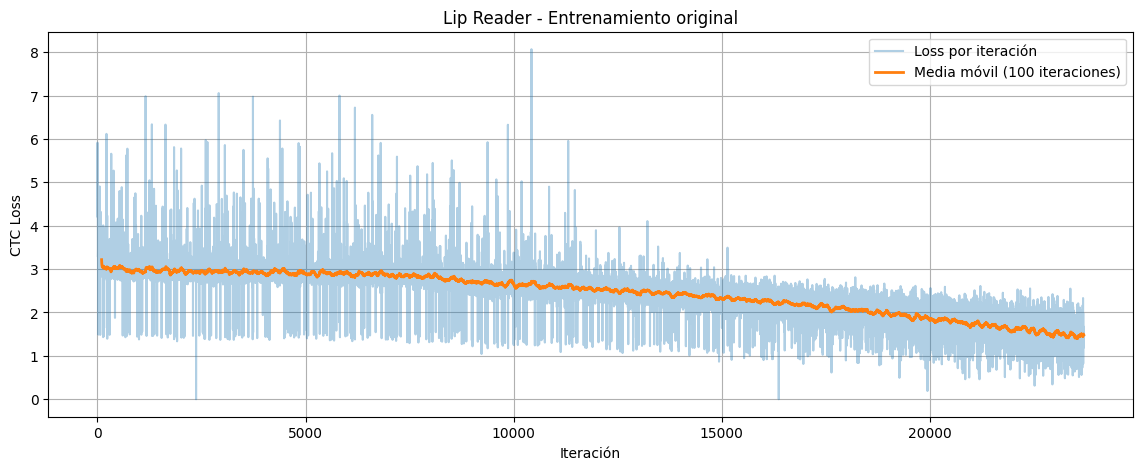

In [42]:
losses = np.array(iter_history)

plt.figure(figsize=(14, 5))

plt.plot(
    range(1, len(losses) + 1),
    losses,
    alpha=0.35,
    label="Loss por iteración"
)

# Media móvil para visualizar la tendencia
window = 100
moving_avg = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    range(window, len(losses) + 1),
    moving_avg,
    linewidth=2,
    label=f"Media móvil ({window} iteraciones)"
)

plt.xlabel("Iteración")
plt.ylabel("CTC Loss")
plt.title("Lip Reader - Entrenamiento original")
plt.legend()
plt.grid()
plt.show()

In [45]:
for name, obj in globals().copy().items():
    if "loader" in name.lower():
        print(name, type(obj))

__loader__ <class 'NoneType'>
DataLoader <class 'type'>
train_loader <class 'torch.utils.data.dataloader.DataLoader'>
test_loader <class 'torch.utils.data.dataloader.DataLoader'>


In [46]:
test_loss_now = evaluate_loss(test_loader)
print(f"Test Loss actual: {test_loss_now:.4f}")

Test Loss actual: 3.4358


# OVERFIT TEST 

In [ ]:
import random
#---------- configuración ----------
N_CLIPS = 200             # cantidad de clips fijos (subilo a 100, 200... de a escalones)
MAX_FRAMES = 150         # descarta clips largos para que sea rápido
BATCH = 4
LR = 3e-4
MAX_EPOCHS = 300
EVAL_EVERY = 10
OVERFIT_DROPOUT = 0.0    # 0.0 = sin dropout | probá 0.1 y 0.5 para ver cuánto frena
SEED = 0

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

In [ ]:
# ---------- helpers ----------
def min_frames_needed_text(text):
    """Frames mínimos para alinear el texto: 1 por caracter + 1 blank entre iguales seguidos."""
    text = str(text)
    repeats = sum(1 for a, b in zip(text[:-1], text[1:]) if a == b)
    return len(text) + repeats


def ctc_collapse(tokens):
    """Greedy CTC: colapsa repetidos y elimina blanks."""
    out, prev = [], None
    for t in tokens:
        if t != prev and t != BLANK_IDX:
            out.append(idx_to_char[t])
        prev = t
    return "".join(out)


def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]



Seleccion de clips 

In [ ]:

pool = train_df.copy()
pool["needed"] = pool["label"].astype(str).apply(min_frames_needed_text)
pool = pool[(pool["needed"] <= pool["frames"] * 0.9) & (pool["frames"] <= MAX_FRAMES)]

assert len(pool) >= N_CLIPS, f"Solo hay {len(pool)} clips válidos; bajá N_CLIPS o subí MAX_FRAMES"

sub = pool.sample(N_CLIPS, random_state=SEED).reset_index(drop=True)

# Se decodifica cada video UNA sola vez y queda en memoria (CPU)
dataset = ViSpeRDataset(sub)
samples = [dataset[i] for i in range(len(dataset))]

print(f"Clips: {len(samples)} | frames: min {sub['frames'].min()}, max {sub['frames'].max()}")
print(f"Caracteres: min {sub['label'].str.len().min()}, max {sub['label'].str.len().max()}")




nuevo modelo

In [ ]:
model_of = LipReadingModel( 
    in_channels=INPUT_CHANNELS,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)  # mismos params que la original

# Fija la probabilidad de todos los dropout sin tocar la clase
for m in model_of.modules():
    if isinstance(m, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
        m.p = OVERFIT_DROPOUT

ctc = nn.CTCLoss(blank=BLANK_IDX, reduction="mean", zero_infinity=True)
opt = optim.Adam(model_of.parameters(), lr=LR)




In [ ]:
@torch.no_grad()
def evaluate_all():
    model_of.eval()
    total_err, total_chars, results = 0, 0, []

    for start in range(0, len(samples), BATCH):
        batch = collate_fn(samples[start:start + BATCH])
        videos = batch["videos"].to(DEVICE)
        input_lengths = batch["input_lengths"]

        log_probs = model_of(videos, input_lengths)          # (T, B, V)
        preds = log_probs.argmax(dim=-1).cpu()               # (T, B)

        for i, text in enumerate(batch["texts"]):
            T_i = input_lengths[i].item()
            pred = ctc_collapse(preds[:T_i, i].tolist())
            err = levenshtein(text, pred)
            total_err += err
            total_chars += len(text)
            results.append((text, pred, err))

    model_of.train()
    return total_err / total_chars, results



In [ ]:
# ---------- entrenamiento ----------
history = []
model_of.train()

for epoch in range(1, MAX_EPOCHS + 1):

    perm = torch.randperm(len(samples)).tolist()
    epoch_loss, n_batches = 0.0, 0

    for start in range(0, len(perm), BATCH):
        chunk = [samples[j] for j in perm[start:start + BATCH]]
        if len(chunk) < 2:          # evita un batch de 1 clip (ruidoso con BatchNorm)
            continue

        batch = collate_fn(chunk)
        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)
        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        opt.zero_grad()
        log_probs = model_of(videos, input_lengths)
        loss = ctc(log_probs, targets, input_lengths, target_lengths)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_of.parameters(), max_norm=5.0)
        opt.step()

        epoch_loss += loss.item()
        n_batches += 1

    train_loss = epoch_loss / max(n_batches, 1)
    history.append(train_loss)

    if epoch == 1 or epoch % EVAL_EVERY == 0:
        cer, results = evaluate_all()
        print(f"\nÉpoca {epoch:3d} | loss train {train_loss:.4f} | CER (eval) {cer:.3f}")
        for text, pred, _ in results[:3]:
            print(f"    REAL: {text!r}")
            print(f"    PRED: {pred!r}")

        if cer == 0.0:
            print("\n✔ Memorizó todos los clips en modo eval.")
            break




In [ ]:
# ---------- resultado final ----------
cer, results = evaluate_all()
print("\n" + "=" * 60)
print(f"FINAL | loss train {history[-1]:.4f} | CER (eval) {cer:.3f}")
print("=" * 60)
for text, pred, err in results:
    print(f"[{err:3d} err] REAL: {text!r}")
    print(f"        PRED: {pred!r}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history) + 1), history)
plt.xlabel("Época")
plt.ylabel("CTC Loss")
plt.title(f"Overfit con {N_CLIPS} clips | dropout={OVERFIT_DROPOUT}")
plt.grid(True)
plt.show()

In [ ]:
print(type(model))
print(epoch)
print(train_loss)

<class '__main__.LipReadingModel'>
1
3.2813383674621583


# CHECKPOINT

In [34]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}, "lipreader_recovered_50_epochs.pth")

In [36]:
checkpoint = torch.load(
    "lipreader_recovered_50_epochs.pth",
    map_location=DEVICE,
    weights_only=True
)

print(checkpoint.keys())

dict_keys(['model_state_dict', 'optimizer_state_dict'])
